# 阶段 2：特征工程（数据挖掘）

用 DuckDB 的 SQL 从 4,500 多万行交易流水中，为每个客户构造特征（`src/features.py`）。所有特征只用截止时间 2019-03-19 0 点之前的信息。

1. 构造特征，写出特征说明表
2. 特征质量检查：缺失、取值范围、高度相关的特征
3. 泄露检查：所有特征在实验组和对照组之间都应该平衡
4. 固定训练集 / 验证集 / 测试集的划分（后面所有阶段共用）
5. 异质性初探：只在训练集上，看短信效应在不同人群里是否不同

说明：镜像数据里没有商品目录表，所以做不了品类偏好特征。

## 2.1 构造特征

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from src.abtest import diff_in_means
from src.balance import smd
from src.config import DATA_PROCESSED, RESULTS, SEED
from src.data import connect, load_clients, load_train
from src.features import CUTOFF, FEATURE_DESC, build_features
from src.plotting import INK_SECONDARY, SERIES, setup_matplotlib, smd_plot

setup_matplotlib()
start = time.time()
features = build_features(connect(), load_clients())
elapsed = time.time() - start
train = load_train().set_index("client_id")
data = train.join(features, how="left")
FEATURES = list(FEATURE_DESC)
assert set(FEATURES) == set(features.columns), set(features.columns) ^ set(FEATURES)
data.to_parquet(DATA_PROCESSED / "features.parquet")
print(f"特征构造用时 {elapsed:.1f} 秒；全部客户 {features.shape[0]:,} 人、{features.shape[1]} 个特征；带实验标签的客户 {len(data):,} 人")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

特征构造用时 25.9 秒；全部客户 400,162 人、43 个特征；带实验标签的客户 200,039 人


## 2.2 特征说明表与质量检查

In [2]:
X = data[FEATURES]
dictionary = pd.DataFrame({
    "分组": [FEATURE_DESC[c][0] for c in FEATURES],
    "含义": [FEATURE_DESC[c][1] for c in FEATURES],
    "缺失比例": X.isna().mean().to_numpy(),
    "中位数": X.median().to_numpy(),
    "最小值": X.min().to_numpy(),
    "最大值": X.max().to_numpy(),
}, index=FEATURES)
dictionary.to_csv(RESULTS / "stage2_feature_dictionary.csv", encoding="utf-8-sig")
dictionary.round(3)

,分组,含义,缺失比例,中位数,最小值,最大值
n_trans,频率与金额,截止日前的交易次数,0.000,15.000,1.000,320.000
total_sum,频率与金额,消费总额,0.000,6102.440,1.040,504490.380
avg_sum,频率与金额,平均每笔交易金额（客单价）,0.000,394.000,1.040,7694.000
std_sum,频率与金额,交易金额的标准差（只有 1 笔交易时为空）,0.019,254.469,0.000,8829.586
max_sum,频率与金额,单笔最大交易金额,0.000,977.010,1.040,29611.480
median_sum,频率与金额,交易金额中位数,0.000,330.950,1.040,7694.000
n_active_days,频率与金额,有交易的天数,0.000,14.000,1.000,115.000
trans_per_week,频率与金额,平均每周交易次数（从第一次交易算起）,0.000,1.096,0.120,26.833
avg_interval_days,频率与金额,平均交易间隔天数,0.000,6.100,0.059,113.000
recency_days,近期活跃度,最近一次交易距截止日的天数,0.000,5.000,1.000,23.000


In [3]:
corr = X.corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(corr.loc[a, b]) > 0.9]
high_corr = pd.DataFrame(pairs, columns=["特征 A", "特征 B", "相关系数"]).sort_values("相关系数", key=abs, ascending=False)
quality = {
    "特征数": len(FEATURES),
    "有缺失的特征": {c: float(v) for c, v in X.isna().mean().items() if v > 0},
    "取值只有一个的特征": [c for c in FEATURES if X[c].nunique() <= 1],
    "相关系数绝对值 > 0.9 的特征对数": len(high_corr),
}
display(high_corr.round(3))
quality

,特征 A,特征 B,相关系数
0,n_trans,n_active_days,0.969
2,avg_sum,median_sum,0.961
6,share_lines_paid_by_points,share_sum_paid_by_points,0.960
3,std_sum,max_sum,0.915
1,total_sum,regular_points_received,0.914
8,share_morning,mean_hour,-0.914
7,avg_items,avg_lines,0.910
4,share_trans_30d,share_sum_30d,0.908
5,share_trans_points_spent,share_lines_paid_by_points,0.901


{'特征数': 43,
 '有缺失的特征': {'std_sum': 0.019096276226135904,
  'share_sum_paid_by_points': 0.0003399337129259794,
  'age': 0.0035193137338219048,
  'days_since_first_redeem': 0.20069086528127014,
  'issue_to_redeem_days': 0.20069086528127014},
 '取值只有一个的特征': [],
 '相关系数绝对值 > 0.9 的特征对数': 9}

## 2.3 泄露检查：特征在两组之间是否平衡

所有特征都来自短信之前，理论上不可能受短信影响，两组应该没有差异。如果某个特征两组差异明显，就说明它很可能用到了短信之后的信息。这个思路和阶段 1 的安慰剂检验一样。

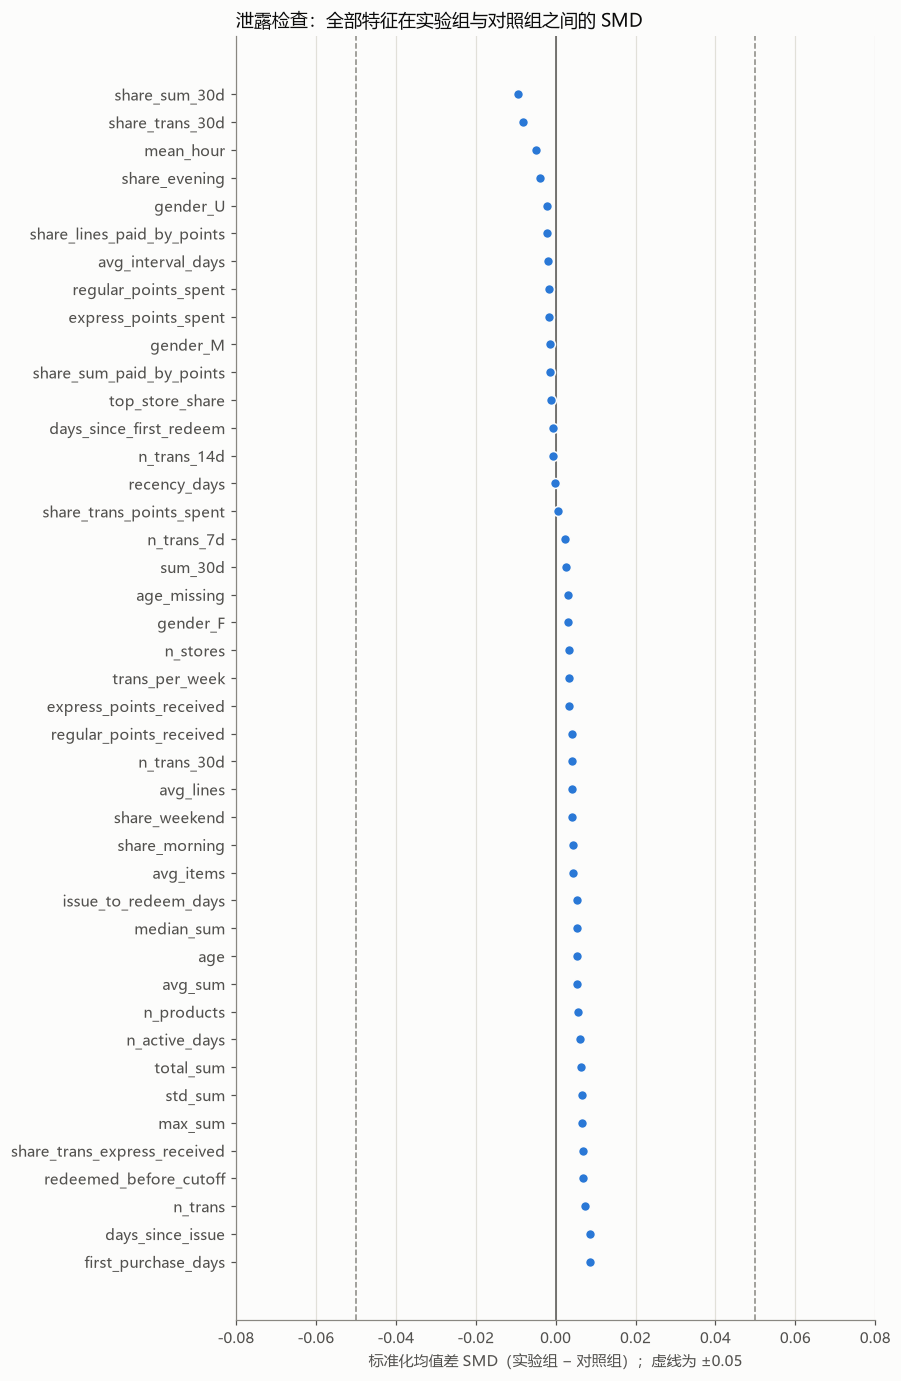

{'最大 |SMD|': 0.009445114474152366,
 '最大 |SMD| 的特征': 'share_sum_30d',
 '|SMD| > 0.05 的特征数': 0}

In [4]:
t_all = data["treatment_flg"]
leak = pd.Series({c: smd(X.loc[t_all == 1, c].dropna(), X.loc[t_all == 0, c].dropna()) for c in FEATURES})
leak_summary = {"最大 |SMD|": float(leak.abs().max()), "最大 |SMD| 的特征": leak.abs().idxmax(),
                "|SMD| > 0.05 的特征数": int((leak.abs() > 0.05).sum())}
fig, ax = smd_plot(leak.sort_values(), threshold=0.05, title="泄露检查：全部特征在实验组与对照组之间的 SMD")
fig.savefig(RESULTS / "stage2_leakage_check.png")
plt.show()
leak_summary

## 2.4 划分训练集 / 验证集 / 测试集

按 60% / 20% / 20% 随机划分，同时按“是否收到短信 × 是否购买”四种组合分层，保证每个集合里四种人的比例一致。
- **训练集**：训练模型；
- **验证集**：挑选模型和参数；
- **测试集**：只在最后评估一次，报告的成绩都来自这里。

In [5]:
strata = data["treatment_flg"].astype(str) + "_" + data["target"].astype(str)
# pandas 3 的字符串索引不能直接交给 scikit-learn，先转成 numpy 数组
ids, s_all = np.asarray(data.index, dtype=object), strata.to_numpy()
idx_train, idx_rest, _, s_rest = train_test_split(ids, s_all, test_size=0.4, random_state=SEED, stratify=s_all)
idx_valid, idx_test = train_test_split(idx_rest, test_size=0.5, random_state=SEED, stratify=s_rest)
split = pd.Series("train", index=data.index, name="split")
split.loc[idx_valid] = "valid"
split.loc[idx_test] = "test"
split.to_frame().to_csv(DATA_PROCESSED / "split.csv")
split_summary = data.assign(split=split).groupby("split").agg(
    人数=("target", "size"), 实验组占比=("treatment_flg", "mean"), 购买率=("target", "mean")).reindex(["train", "valid", "test"])
split_summary["ATE"] = [diff_in_means(data.loc[split == s, "target"], data.loc[split == s, "treatment_flg"])["ATE"]
                        for s in split_summary.index]
split_summary.round(4)

,人数,实验组占比,购买率,ATE
split,,,,
train,120023,0.4998,0.6199,0.0332
valid,40008,0.4998,0.6199,0.0332
test,40008,0.4998,0.6199,0.0332


## 2.5 异质性初探（只用训练集）

把客户按某个特征分成 5 等份，在每一份里分别计算“实验组购买率 − 对照组购买率”。如果不同的人群差异很大，说明短信的效应因人而异，这正是增益模型能发挥作用的前提。

注意：
- 只用训练集，测试集要留到最后。
- 这里看到的只是“效应大小和某个特征相关”，不能说这个特征导致效应变大。

In [6]:
tr = data[split == "train"]
HET = {"recency_days": "最近一次交易距今（天）", "n_trans": "交易次数", "avg_sum": "客单价",
       "age": "年龄", "share_trans_points_spent": "使用积分的交易占比", "days_since_issue": "办卡天数"}
rows = []
for col, label in HET.items():
    q = pd.qcut(tr[col].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    for b in q.cat.categories:
        g = tr[q == b]
        r = diff_in_means(g["target"], g["treatment_flg"])
        rows.append({"特征": col, "含义": label, "分位组": b, "特征中位数": float(g[col].median()), "人数": len(g),
                     "对照组购买率": r["对照组均值"], "ATE": r["ATE"], "标准误": r["标准误"]})
het = pd.DataFrame(rows)
het.to_csv(RESULTS / "stage2_heterogeneity.csv", index=False, encoding="utf-8-sig")
het.pivot(index="分位组", columns="特征", values="ATE").round(4)

特征,age,avg_sum,days_since_issue,n_trans,recency_days,share_trans_points_spent
分位组,,,,,,
Q1,0.0084,0.0573,0.0548,0.0445,0.0216,0.0323
Q2,0.0310,0.0327,0.0362,0.0456,0.0318,0.0278
Q3,0.0247,0.0314,0.0297,0.0279,0.0311,0.0154
Q4,0.0462,0.0243,0.0246,0.0235,0.0390,0.0416
Q5,0.0548,0.0204,0.0209,0.0168,0.0398,0.0469


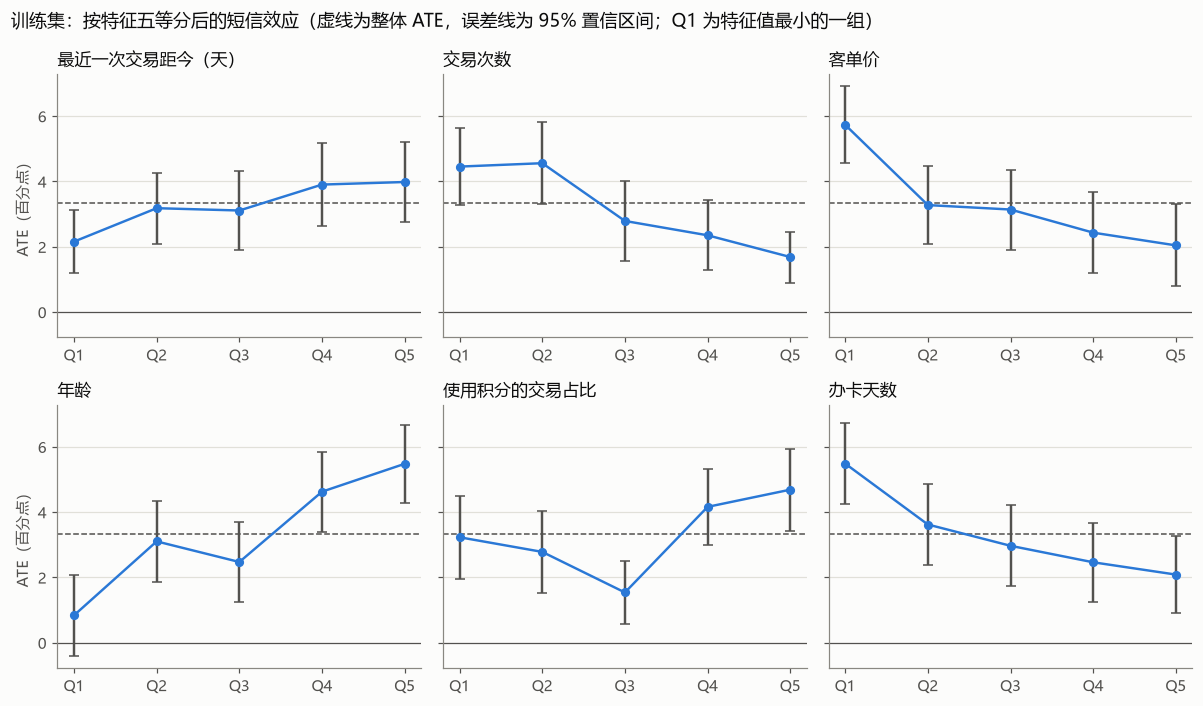

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=True)
overall = diff_in_means(tr["target"], tr["treatment_flg"])["ATE"] * 100
for ax, (col, label) in zip(axes.flat, HET.items()):
    g = het[het["特征"] == col]
    x = np.arange(5)
    ax.errorbar(x, g["ATE"] * 100, yerr=1.96 * g["标准误"] * 100, fmt="o-", color=SERIES[0], ecolor=INK_SECONDARY,
                capsize=3, markersize=5, linewidth=1.6)
    ax.axhline(overall, color=INK_SECONDARY, linestyle="--", linewidth=1)
    ax.axhline(0, color=INK_SECONDARY, linewidth=0.8)
    ax.set_xticks(x, [f"Q{i + 1}" for i in x])
    ax.set_title(f"{label}", loc="left", fontsize=11)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("ATE（百分点）")
fig.suptitle("训练集：按特征五等分后的短信效应（虚线为整体 ATE，误差线为 95% 置信区间；Q1 为特征值最小的一组）",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(RESULTS / "stage2_heterogeneity.png")
plt.show()

## 2.6 保存结果

In [8]:
(RESULTS / "stage2_features_summary.json").write_text(json.dumps({
    "截止时间": CUTOFF, "特征构造用时（秒）": elapsed, "全部客户数": int(features.shape[0]), "特征数": len(FEATURES),
    "带实验标签的客户数": int(len(data)), "质量检查": quality, "泄露检查": leak_summary,
    "划分": json.loads(split_summary.to_json(orient="index", force_ascii=False)),
}, ensure_ascii=False, indent=2), encoding="utf-8")
high_corr.to_csv(RESULTS / "stage2_high_correlation.csv", index=False, encoding="utf-8-sig")
print("已保存：stage2_feature_dictionary.csv、stage2_high_correlation.csv、stage2_leakage_check.png、"
      "stage2_heterogeneity.csv/png、stage2_features_summary.json；data/processed/features.parquet、split.csv")

已保存：stage2_feature_dictionary.csv、stage2_high_correlation.csv、stage2_leakage_check.png、stage2_heterogeneity.csv/png、stage2_features_summary.json；data/processed/features.parquet、split.csv
